# 14. Final Models and the One-Time Holdout Evaluation

Everything so far has been compared with cross-validation. This notebook makes the final choices **using the training portion only**, then evaluates them **once** on the untouched 20% holdout set (885 students). These are the only holdout numbers that should appear in the final presentation.

There are two final models, because the project answers two questions:

| Model | Question | Chosen in |
|---|---|---|
| **Final classifier** (three classes) | Can we classify a student's final outcome: Dropout, Enrolled or Graduate? | 14.1, using a rule fixed in advance |
| **Early-warning model** (binary) | Which students should advisors contact? | Notebook 13: recalibrated binary logistic regression, top 20% / 30% of students by risk |

**Selection rule for the classifier (fixed before looking at the holdout):** the model with the highest mean **macro F1** in 5-fold cross-validation on the training portion, **after Semester 1** (the stage where an intervention is still possible). Macro F1 has been the primary metric for the whole project.

**What's reported:** holdout macro F1, accuracy and per-class recall with 95% bootstrap confidence intervals, compared against the cross-validation estimate; then which features drive the model (permutation importance, SHAP values, partial dependence on approved units).

## 14.0 Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import warnings
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

from src.models import get_logistic_regression, get_random_forest, get_xgboost
from src.plotting import MODEL_ORDER, OUTCOME_ORDER, OUTCOME_PALETTE
from src.preprocessing import TARGET_COL, build_model_pipeline, get_feature_availability_sets, load_data

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
CLASSES = OUTCOME_ORDER                       # ["Dropout", "Enrolled", "Graduate"]
STAGES = ["Day 1", "After Semester 1", "Full Data"]
SELECTION_STAGE = "After Semester 1"
N_BOOT = 2000
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
feature_sets = get_feature_availability_sets(df)
y_all = df[TARGET_COL]
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.20,
                                       random_state=RANDOM_STATE, stratify=y_all)
y_train, y_test = y_all.loc[train_idx], y_all.loc[test_idx]
encoder = LabelEncoder().fit(CLASSES)
print(f"Training: {len(train_idx)} | Holdout: {len(test_idx)} "
      f"({', '.join(f'{c} {n}' for c, n in y_test.value_counts().reindex(CLASSES).items())})")

Training: 3539 | Holdout: 885 (Dropout 284, Enrolled 159, Graduate 442)


In [3]:
MODELS = {
    "Logistic Regression": (get_logistic_regression, True),
    "Random Forest": (get_random_forest, False),
    "XGBoost": (get_xgboost, False),
}


class ThreeClassModel:
    """Wraps the shared pipeline so every model takes and returns outcome labels
    (XGBoost needs integer labels and balanced sample weights internally)."""

    def __init__(self, model_name, cols):
        factory, scale = MODELS[model_name]
        self.model_name, self.cols = model_name, cols
        self.pipe = build_model_pipeline(model=factory(RANDOM_STATE), feature_cols=cols, scale_numeric=scale)
        self.classes_ = np.array(CLASSES)

    def fit(self, X, y):
        if self.model_name == "XGBoost":
            y_enc = encoder.transform(y)
            self.pipe.fit(X[self.cols], y_enc, model__sample_weight=compute_sample_weight("balanced", y_enc))
        else:
            self.pipe.fit(X[self.cols], y)
        return self

    def predict_proba(self, X):
        proba = self.pipe.predict_proba(X[self.cols])
        order = (encoder.inverse_transform(self.pipe.named_steps["model"].classes_.astype(int))
                 if self.model_name == "XGBoost" else self.pipe.named_steps["model"].classes_)
        return pd.DataFrame(proba, index=X.index, columns=order)[CLASSES].to_numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

    # sklearn's permutation_importance only needs fit/predict/score-like behavior
    def score(self, X, y):
        return f1_score(y, self.predict(X), average="macro")

## 14.1 Choose the final classifier (training portion only)

The cross-validation in notebook 07 used all 4,424 students, including the holdout. To keep the choice independent of the holdout, the selection is redone here on the 3,539 training students, using the same rule for every model.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_train_all = df.loc[train_idx]

sel_rows = []
for model_name in MODELS:
    fold_f1, fold_rec = [], []
    for fit_pos, val_pos in cv.split(X_train_all, y_train):
        m = ThreeClassModel(model_name, feature_sets[SELECTION_STAGE]).fit(
            X_train_all.iloc[fit_pos], y_train.iloc[fit_pos])
        pred = m.predict(X_train_all.iloc[val_pos])
        truth = y_train.iloc[val_pos]
        fold_f1.append(f1_score(truth, pred, average="macro"))
        fold_rec.append(recall_score(truth, pred, labels=CLASSES, average=None))
    rec = np.mean(fold_rec, axis=0)
    sel_rows.append({"Model": model_name, "CV macro F1": np.mean(fold_f1), "SD": np.std(fold_f1, ddof=1),
                     **{f"CV {c} recall": r for c, r in zip(CLASSES, rec)}})

selection = pd.DataFrame(sel_rows).set_index("Model").reindex(MODEL_ORDER)
display(selection.round(3))

FINAL_MODEL = selection["CV macro F1"].idxmax()
best = selection.loc[FINAL_MODEL]
within_1sd = selection.index[selection["CV macro F1"] >= best["CV macro F1"] - best["SD"]].tolist()
print(f"Final classifier (highest CV macro F1 after Semester 1): {FINAL_MODEL}")
print(f"Models within one SD of it: {within_1sd}")

,CV macro F1,SD,CV Dropout recall,CV Enrolled recall,CV Graduate recall
Model,,,,,
Logistic Regression,0.679,0.023,0.708,0.553,0.792
Random Forest,0.688,0.022,0.733,0.438,0.873
XGBoost,0.700,0.020,0.708,0.603,0.810


Final classifier (highest CV macro F1 after Semester 1): XGBoost
Models within one SD of it: ['Random Forest', 'XGBoost']


**Reading 14.1:** **XGBoost** has the highest cross-validated macro F1 after Semester 1 (0.700 ± 0.020), ahead of Random Forest (0.688) and logistic regression (0.679).

- Random Forest is within one standard deviation, but it catches only 44% of Enrolled students, compared with XGBoost's 60%, because it leans toward Graduate (notebook 07).
- Logistic regression is about one standard deviation lower. It would be the choice if interpretability mattered more than the last 0.02 of macro F1. Its coefficients are hard to read here anyway because of the multicollinearity in the units columns (assumptions notebook, section 2), so permutation importance and SHAP (14.4) explain XGBoost just as well.

So the rule fixed in advance picks **XGBoost**, which is also the most balanced across the three outcomes.

## 14.2 Holdout evaluation of the final classifier

The final classifier is refit on the full training portion at each stage and scored once on the holdout. 95% confidence intervals come from 2,000 bootstrap resamples of the 885 holdout students, so they show how much these numbers would move with a different holdout set.

In [5]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=N_BOOT, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats_ = [metric(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(stats_, [2.5, 97.5])


def class_recall(cls):
    return partial(recall_score, labels=[cls], average="macro")


METRICS = {
    "Macro F1": partial(f1_score, average="macro"),
    "Accuracy": accuracy_score,
    **{f"{c} recall": class_recall(c) for c in CLASSES},
}

cv_stage = pd.read_csv(OUT_DIR / "model_cv_by_stage.csv").set_index(["Stage", "Model"])  # notebook 07

final_fits, holdout_pred, holdout_rows = {}, {}, []
for stage in STAGES:
    m = ThreeClassModel(FINAL_MODEL, feature_sets[stage]).fit(df.loc[train_idx], y_train)
    final_fits[stage] = m
    pred = pd.Series(m.predict(df.loc[test_idx]), index=test_idx)
    holdout_pred[stage] = pred
    for name, fn in METRICS.items():
        lo, hi = bootstrap_ci(y_test, pred, fn)
        cv_col = {"Macro F1": "Macro F1", "Accuracy": "Accuracy"}.get(name, name.replace(" recall", " Recall"))
        holdout_rows.append({"Stage": stage, "Metric": name, "Holdout": fn(y_test, pred),
                             "95% CI": f"{lo:.3f} to {hi:.3f}",
                             "CV estimate (nb 07)": cv_stage.loc[(stage, FINAL_MODEL), cv_col]})

holdout = pd.DataFrame(holdout_rows)
holdout["Holdout − CV"] = holdout["Holdout"] - holdout["CV estimate (nb 07)"]
holdout.to_csv(OUT_DIR / "final_model_holdout_metrics.csv", index=False)
display(holdout.pivot(index="Metric", columns="Stage", values="Holdout")
        .reindex(index=list(METRICS), columns=STAGES).round(3))
display(holdout.round(3))

Stage,Day 1,After Semester 1,Full Data
Metric,,,
Macro F1,0.561,0.667,0.702
Accuracy,0.592,0.705,0.737
Dropout recall,0.570,0.648,0.694
Enrolled recall,0.497,0.616,0.660
Graduate recall,0.640,0.774,0.792


,Stage,Metric,Holdout,95% CI,CV estimate (nb 07),Holdout − CV
0,Day 1,Macro F1,0.561,0.524 to 0.594,0.578,-0.017
1,Day 1,Accuracy,0.592,0.556 to 0.625,0.613,-0.021
2,Day 1,Dropout recall,0.570,0.512 to 0.627,0.564,0.007
3,Day 1,Enrolled recall,0.497,0.417 to 0.575,0.519,-0.022
4,Day 1,Graduate recall,0.640,0.596 to 0.685,0.680,-0.039
5,After Semester 1,Macro F1,0.667,0.632 to 0.698,0.689,-0.022
6,After Semester 1,Accuracy,0.705,0.673 to 0.734,0.731,-0.026
7,After Semester 1,Dropout recall,0.648,0.589 to 0.702,0.685,-0.037
8,After Semester 1,Enrolled recall,0.616,0.539 to 0.693,0.588,0.028
9,After Semester 1,Graduate recall,0.774,0.733 to 0.813,0.812,-0.038


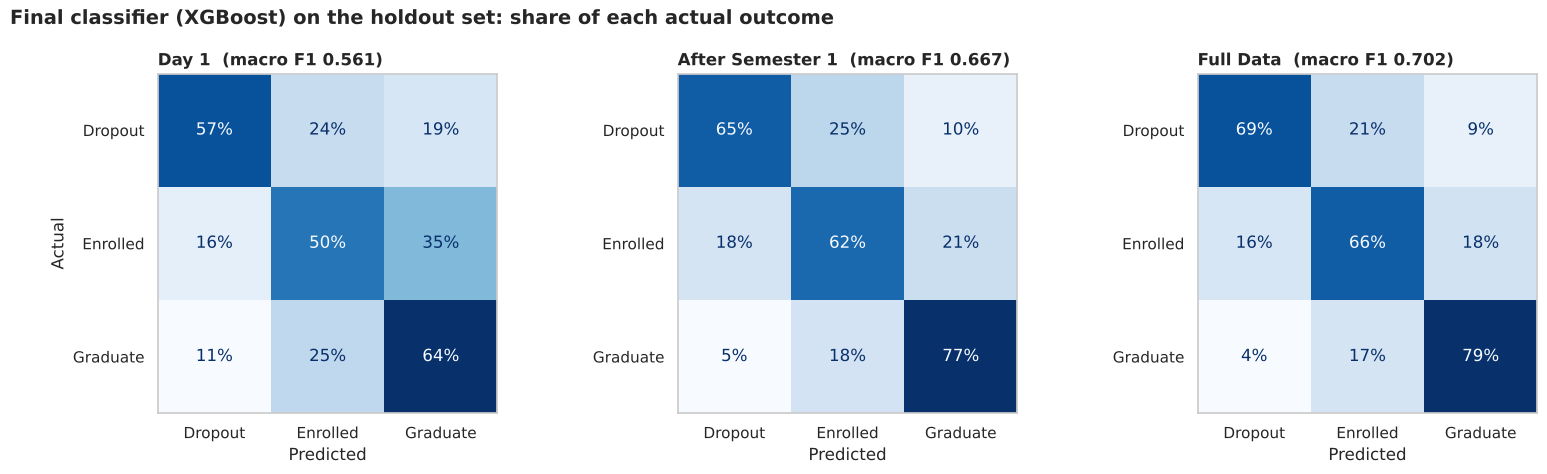

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, stage in zip(axes, STAGES):
    cm = confusion_matrix(y_test, holdout_pred[stage], labels=CLASSES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".0%")
    mf1 = f1_score(y_test, holdout_pred[stage], average="macro")
    ax.set_title(f"{stage}  (macro F1 {mf1:.3f})", fontsize=12, fontweight="bold", loc="left")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual" if ax is axes[0] else "")
    ax.grid(False)
fig.suptitle(f"Final classifier ({FINAL_MODEL}) on the holdout set: share of each actual outcome",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "final_model_holdout_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 14.2: the holdout confirms the cross-validation results.**

| Stage | Holdout macro F1 (95% CI) | Accuracy | Dropout recall | Enrolled recall | Graduate recall |
|---|---|---|---|---|---|
| Day 1 | 0.561 (0.524–0.594) | 59.2% | 57.0% | 49.7% | 64.0% |
| **After Semester 1** | **0.667 (0.632–0.698)** | **70.5%** | **64.8%** | **61.6%** | **77.4%** |
| Full Data | 0.702 (0.667–0.731) | 73.7% | 69.4% | 66.0% | 79.2% |

- **Holdout scores are about 0.02 below the cross-validation estimates** at every stage, but every cross-validation estimate falls inside the holdout's 95% confidence interval. That's the normal size of difference between one 885-student sample and a cross-validation average, not a sign of overfitting.
- **The same story holds on new students:** Semester 1 data adds about 0.11 macro F1 and Semester 2 only about 0.035 more.
- **Enrolled errors go both ways:** after Semester 1, 18% of Enrolled students are predicted Dropout and 21% Graduate, while a quarter of actual dropouts are predicted Enrolled. That's the in-between pattern from notebooks 09 and 11.
- These numbers match notebooks 09 and 10, which used the same split and the same XGBoost settings.

## 14.3 Holdout evaluation of the early-warning model

The early-warning model from notebook 13 is a **recalibrated binary logistic regression** (Dropout vs. not, isotonic calibration). The outreach list is sized by capacity, and the **cutoff score is fixed from the training portion**: the risk score above which the top 20% (or 30%) of training students fall, using out-of-fold scores. That cutoff is then applied to the holdout, as a school would do with a new cohort.

In [7]:
def warning_model(cols):
    factory, scale = MODELS["Logistic Regression"]
    pipe = build_model_pipeline(model=factory(RANDOM_STATE), feature_cols=cols, scale_numeric=scale)
    return CalibratedClassifierCV(pipe, method="isotonic", cv=3)


is_drop_train = (y_train == "Dropout").astype(int)
is_drop_test = (y_test == "Dropout").astype(int)
warn_rows, warn_scores = [], {}
for stage in ["Day 1", "After Semester 1"]:
    cols = feature_sets[stage]
    oof = cross_val_predict(warning_model(cols), df.loc[train_idx, cols], is_drop_train, cv=cv,
                            method="predict_proba")[:, 1]
    model = warning_model(cols).fit(df.loc[train_idx, cols], is_drop_train)
    score = pd.Series(model.predict_proba(df.loc[test_idx, cols])[:, 1], index=test_idx)
    warn_scores[stage] = score
    ap, auc = average_precision_score(is_drop_test, score), roc_auc_score(is_drop_test, score)
    for capacity in [0.20, 0.30]:
        cutoff = np.quantile(oof, 1 - capacity)
        flagged = score >= cutoff
        tp = int((flagged & (is_drop_test == 1)).sum())
        warn_rows.append({"Stage": stage, "Planned capacity": f"{capacity:.0%}", "Cutoff risk": cutoff,
                          "Share flagged": flagged.mean(), "Students flagged": int(flagged.sum()),
                          "Dropouts reached (recall)": tp / is_drop_test.sum(),
                          "Flagged who drop out (precision)": tp / max(flagged.sum(), 1),
                          "Dropouts missed": int(is_drop_test.sum()) - tp,
                          "Average precision": ap, "ROC AUC": auc})

warning = pd.DataFrame(warn_rows)
warning.to_csv(OUT_DIR / "final_warning_holdout.csv", index=False)
print(f"Holdout dropouts: {int(is_drop_test.sum())} of {len(test_idx)}")
display(warning.round(3))

cv13 = pd.read_csv(OUT_DIR / "binary_capacity_cv.csv")
cv13 = cv13[(cv13["Model"] == "Logistic Regression") & (cv13["Approach"] == "Binary Dropout vs. not")
            & cv13["Students contacted"].isin(["20%", "30%"])]
print("For comparison, notebook 13's out-of-fold estimates (training portion):")
display(cv13[["Stage", "Students contacted", "Recall", "Precision"]].round(3))

Holdout dropouts: 284 of 885


,Stage,Planned capacity,Cutoff risk,Share flagged,Students flagged,Dropouts reached (recall),Flagged who drop out (precision),Dropouts missed,Average precision,ROC AUC
0,Day 1,20%,0.518,0.199,176,0.468,0.756,151,0.732,0.817
1,Day 1,30%,0.375,0.292,258,0.613,0.674,110,0.732,0.817
2,After Semester 1,20%,0.694,0.199,176,0.567,0.915,123,0.859,0.904
3,After Semester 1,30%,0.416,0.312,276,0.757,0.779,69,0.859,0.904


For comparison, notebook 13's out-of-fold estimates (training portion):


,Stage,Students contacted,Recall,Precision
5,Day 1,20%,0.479,0.770
6,Day 1,30%,0.624,0.668
29,After Semester 1,20%,0.573,0.919
30,After Semester 1,30%,0.745,0.798


**Reading 14.3: the early-warning numbers hold up on new students.**

| Stage | Planned share contacted | Actual share flagged | Dropouts reached | Flagged who drop out |
|---|---|---|---|---|
| Day 1 | 20% | 19.9% | 46.8% | 75.6% |
| Day 1 | 30% | 29.2% | 61.3% | 67.4% |
| **After Semester 1** | **20%** | **19.9%** | **56.7%** | **91.5%** |
| After Semester 1 | 30% | 31.2% | 75.7% | 77.9% |

- The cutoff scores were set from the training students and still flag almost exactly the planned share of the holdout, so the cutoff carries over to a new cohort.
- Holdout results are within about 1–2 points of notebook 13's training estimates, so **the headline is confirmed:** after Semester 1, contacting the 20% of students with the highest risk reaches **57%** of eventual dropouts, and **9 in 10** of those contacted do drop out.
- Ranking quality on the holdout: average precision 0.859 and ROC AUC 0.904 after Semester 1 (0.732 and 0.817 on Day 1).

## 14.4 What drives the final classifier?

Three complementary views, all for the final classifier **after Semester 1**:

1. **Permutation importance (holdout):** shuffle one original column at a time and measure how much holdout macro F1 drops. Categorical variables are shuffled as a whole (all their one-hot columns together), so every variable is judged on the same footing. Repeated 20 times.
2. **SHAP values:** how much each feature pushes an individual student's predicted risk of **Dropout** up or down.
3. **Partial dependence:** how the predicted probability of each outcome changes with Semester 1 approved units, holding everything else at its observed values.

Correlated features share credit in permutation importance (shuffling one, the model can lean on its partner), so the units variables may each look less important than they are together; notebook 08's group ablation is the better guide to their combined value.

,Feature,Drop in macro F1,SD
0,Curricular units 1st sem (approved),0.1802,0.0106
1,Tuition fees up to date,0.0555,0.0073
2,Curricular units 1st sem (grade),0.0222,0.0086
3,Course,0.0195,0.0039
4,Curricular units 1st sem (enrolled),0.0176,0.0055
5,Curricular units 1st sem (evaluations),0.0157,0.0083
6,Age at enrollment,0.0110,0.0056
7,Scholarship holder,0.0105,0.0052
8,GDP,0.0083,0.0036
9,Mother's qualification,0.0068,0.0031


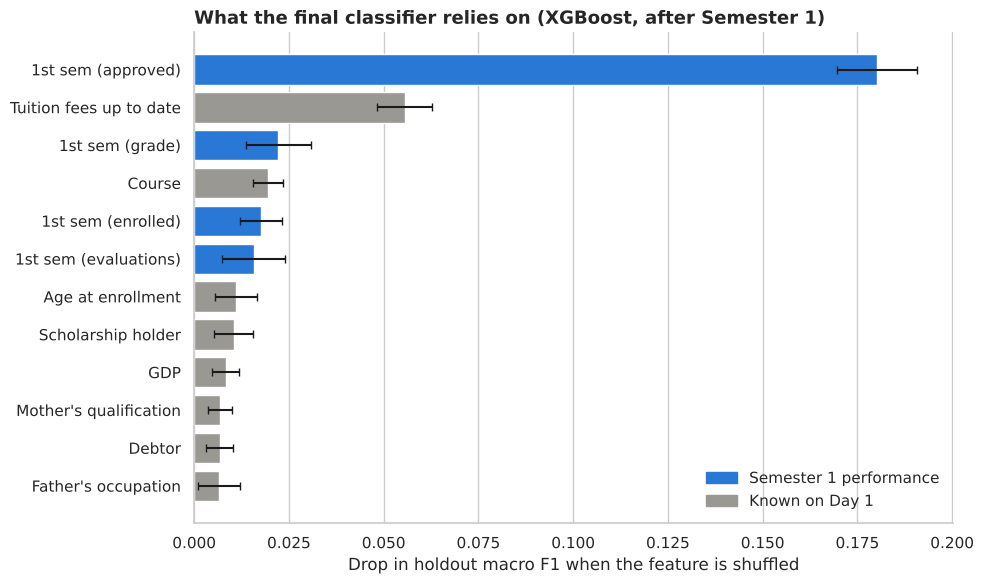

In [8]:
final_sem1 = final_fits[SELECTION_STAGE]
X_test_sem1 = df.loc[test_idx, feature_sets[SELECTION_STAGE]]
perm = permutation_importance(final_sem1, X_test_sem1, y_test, scoring=lambda est, X, y: est.score(X, y),
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"Feature": X_test_sem1.columns, "Drop in macro F1": perm.importances_mean,
                            "SD": perm.importances_std})
              .sort_values("Drop in macro F1", ascending=False).reset_index(drop=True))
importance.to_csv(OUT_DIR / "final_model_permutation_importance.csv", index=False)
display(importance.head(12).round(4))

top = importance.head(12).iloc[::-1]
sem1_color, day1_color = "#2a78d6", "#9a9893"
colors = [sem1_color if "1st sem" in f else day1_color for f in top["Feature"]]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["Feature"].str.replace("Curricular units ", "", regex=False), top["Drop in macro F1"],
        xerr=top["SD"], color=colors, capsize=3)
ax.set_xlabel("Drop in holdout macro F1 when the feature is shuffled")
ax.set_title(f"What the final classifier relies on ({FINAL_MODEL}, after Semester 1)", loc="left",
             fontsize=13, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [sem1_color, day1_color]]
ax.legend(handles, ["Semester 1 performance", "Known on Day 1"], loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "final_model_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


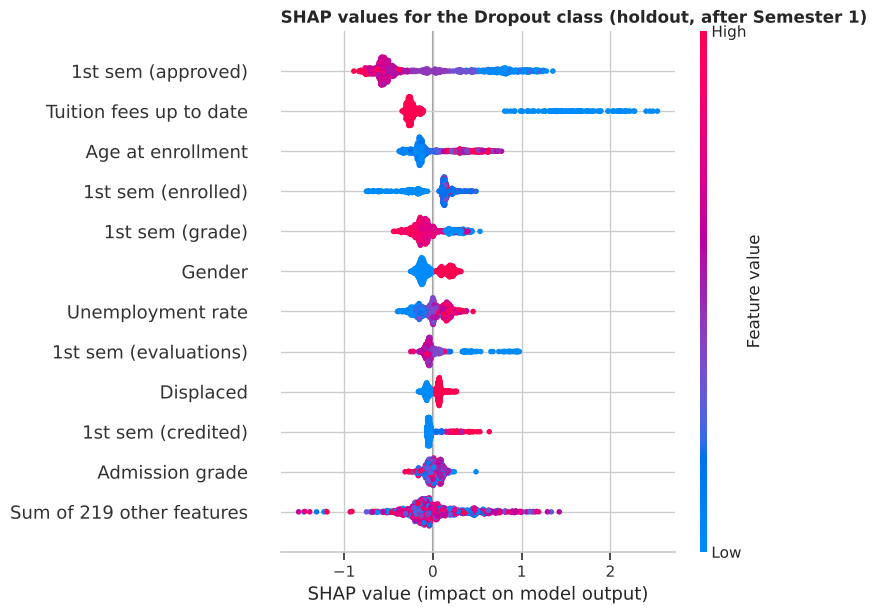

In [9]:
try:
    import shap
except ImportError:
    shap = None
    print("shap is not installed (it is listed in requirements.txt): `pip install shap` to run this cell.")

if shap is not None and FINAL_MODEL in {"XGBoost", "Random Forest"}:
    preprocess = final_sem1.pipe.named_steps["preprocess"]
    X_t = pd.DataFrame(preprocess.transform(X_test_sem1),
                       columns=[c.split("__", 1)[1].replace("Curricular units ", "")
                                for c in preprocess.get_feature_names_out()],
                       index=X_test_sem1.index)
    explainer = shap.TreeExplainer(final_sem1.pipe.named_steps["model"])
    sv = explainer(X_t)
    dropout_col = 0 if FINAL_MODEL == "XGBoost" else list(final_sem1.pipe.named_steps["model"].classes_).index("Dropout")
    plt.figure()
    shap.plots.beeswarm(sv[:, :, dropout_col], max_display=12, show=False)
    plt.title("SHAP values for the Dropout class (holdout, after Semester 1)", loc="left",
              fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "final_model_shap_dropout.png", dpi=200, bbox_inches="tight")
    plt.show()
elif shap is not None:
    print(f"SHAP's tree explainer doesn't apply to {FINAL_MODEL}; permutation importance above covers it.")

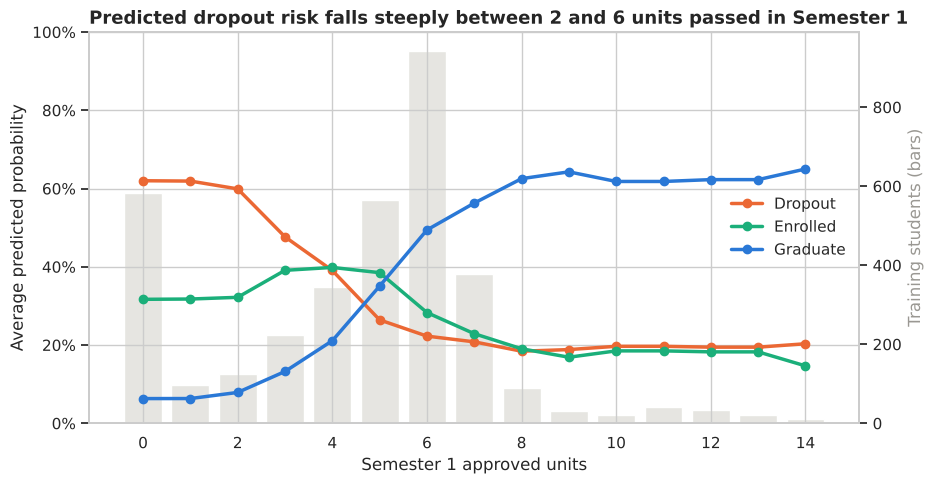

,Dropout,Enrolled,Graduate
Curricular units 1st sem (approved),,,
0,0.620,0.317,0.063
1,0.619,0.318,0.063
2,0.599,0.322,0.079
3,0.477,0.391,0.132
4,0.391,0.398,0.211
5,0.264,0.385,0.351
6,0.223,0.283,0.494
7,0.208,0.229,0.563
8,0.184,0.190,0.625


In [10]:
feature = "Curricular units 1st sem (approved)"
X_train_sem1 = df.loc[train_idx, feature_sets[SELECTION_STAGE]]
grid = np.arange(0, int(X_train_sem1[feature].quantile(0.99)) + 1)


# Partial dependence by hand: set every training student's approved units to each grid value
# and average the predicted probabilities (the same definition sklearn uses).
pdp = []
for v in grid:
    X_mod = X_train_sem1.assign(**{feature: v})
    pdp.append(final_sem1.predict_proba(X_mod).mean(axis=0))
pdp = pd.DataFrame(pdp, index=pd.Index(grid, name=feature), columns=CLASSES)

fig, ax = plt.subplots(figsize=(9.5, 5))
for k, cls in enumerate(CLASSES):
    ax.plot(grid, pdp[cls], marker="o", lw=2.5, color=OUTCOME_PALETTE[cls], label=cls)
counts = X_train_sem1[feature].value_counts().reindex(grid, fill_value=0)
ax2 = ax.twinx()
ax2.bar(grid, counts, color="#e6e5e1", width=0.8, zorder=0)
ax2.set_ylabel("Training students (bars)", color="#9a9893")
ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
ax.set_xlabel("Semester 1 approved units")
ax.set_ylabel("Average predicted probability")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="center right")
ax.set_title("Predicted dropout risk falls steeply between 2 and 6 units passed in Semester 1", loc="left",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "final_model_pdp_approved_units.png", dpi=200, bbox_inches="tight")
plt.show()
display(pdp.round(3))

**Reading 14.4:**

- **Semester 1 approved units dominate.** Shuffling them drops holdout macro F1 by 0.18 (from 0.667 to about 0.49), more than three times as much as the next feature. This matches notebook 08 (approved units add the most) and notebook 12 (passing fewer units is the real warning sign).
- **Tuition fees up to date** is the strongest Day 1 feature (0.056), then the Semester 1 grade, course, and units enrolled and evaluated (about 0.02 each). Every other Day 1 variable is under 0.012.
- **SHAP (Dropout class):**
  - Few approved units and tuition not up to date push a student strongly toward Dropout.
  - Older age and Gender = 1 (male in the UCI coding) push moderately toward Dropout.
  - The unemployment rate also shows up; notebook 11 showed that the macro variables are really enrollment-cohort indicators.
- **Partial dependence on approved units:**
  - Predicted dropout risk is about 60% for 0–2 units passed.
  - It falls steeply between 3 and 6 units, and levels off around 20% from 7 units on.
  - Predicted Graduate rises from 6% to about 63%.
  - **Enrolled peaks at 3–5 units (about 40%)**: students who pass *some* but not all their units are exactly the in-between group the models find hardest.
  - Few students pass more than 8 units (grey bars), so the flat right end rests on little data.
- These show what the **model** relies on, not what causes dropout. A student passing more units probably reflects engagement, not a lever that guarantees graduation.

## 14.5 Save predictions for notebook 15

In [11]:
preds = pd.DataFrame({"Actual": y_test})
for stage in STAGES:
    proba = final_fits[stage].predict_proba(df.loc[test_idx])
    preds[f"Predicted ({stage})"] = holdout_pred[stage]
    for k, cls in enumerate(CLASSES):
        preds[f"P({cls}) ({stage})"] = proba[:, k]
for stage, score in warn_scores.items():
    preds[f"Warning risk ({stage})"] = score
for _, r in warning.iterrows():
    preds[f"Flagged {r['Planned capacity']} ({r['Stage']})"] = warn_scores[r["Stage"]] >= r["Cutoff risk"]
preds.index.name = "row"
preds.to_csv(OUT_DIR / "final_model_holdout_predictions.csv")
print(f"Saved {preds.shape} to data/processed/final_model_holdout_predictions.csv; final classifier = {FINAL_MODEL}")

Saved (885, 19) to data/processed/final_model_holdout_predictions.csv; final classifier = XGBoost


## 14.6 Answer

| | Final choice | Holdout result (885 students, evaluated once) |
|---|---|---|
| **Final classifier** | XGBoost, chosen by the highest training cross-validation macro F1 after Semester 1 | After Semester 1: **macro F1 0.667** (95% CI 0.632–0.698), accuracy 70.5%, recall Dropout 65% / Enrolled 62% / Graduate 77%. Day 1: 0.561; Full Data: 0.702 |
| **Early-warning model** | Recalibrated binary logistic regression (notebook 13), top 20% by risk, cutoff set from training data | After Semester 1: reaches **57% of dropouts**, and **92% of those flagged drop out** (top 30%: 76% reached, 78% precision) |
| **Main driver** | Semester 1 approved units | Shuffling it costs 0.18 macro F1; predicted dropout risk falls from about 60% to 20% between 2 and 7 units passed |

**One-sentence takeaways for the final presentation:**

- *Classification:* "Our final model classifies a student's outcome correctly 70% of the time after one semester (macro F1 0.67), and the Enrolled students in between remain the hardest to predict."
- *Early warning:* "After Semester 1, contacting the 20% of students with the highest predicted risk reaches 57% of eventual dropouts, and 9 in 10 of those contacted would otherwise drop out."
- *Why:* "The strongest signal is how many units a student passes in their first semester."

**Limitations:**

- This is one holdout set of 885 students; the confidence intervals show about ±0.03 of uncertainty in macro F1.
- XGBoost is untuned (default project settings), so its score may be a slight underestimate.
- The data come from one Portuguese institution, and "Enrolled" is measured at the end of the normal course length.
- Feature importance describes the model, not causes.

Outputs: `data/processed/final_model_holdout_metrics.csv`, `final_warning_holdout.csv`, `final_model_permutation_importance.csv`, and `final_model_holdout_predictions.csv` (for notebook 15); figures `final_model_holdout_confusion.png`, `final_model_permutation_importance.png`, `final_model_shap_dropout.png`, `final_model_pdp_approved_units.png`.